## Any arbitrary given to us a spacetime metric

## $$
ds^2 = g_{\rho\sigma}dx^{\rho}dx^{\sigma}
$$

## but now it is for Schw case

/var/folders/14/nbfg0mr53lzgsqtmv1m6z7zc0000gn/T/ipykernel_6349/2398285159.py:68: RuntimeWarning: invalid value encountered in sqrt
  return 1/(np.sqrt(-gtt(r) - 2*w*gtp(r)-w**2*gpp(r,theta)))


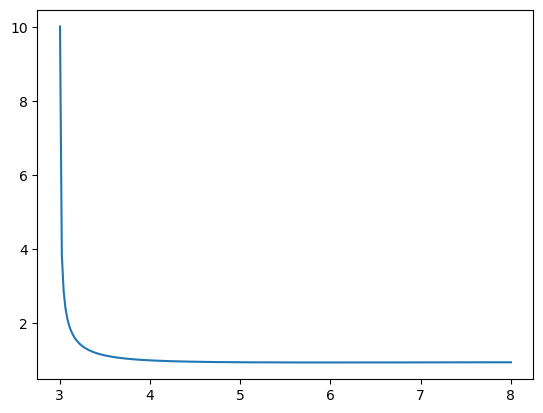

In [130]:
import numpy as np
import matplotlib.pyplot as plt

# ########     metrika    #########
def gtt(r):
    return (-1+2/r)

def grr(r):
    return 1/(1-2/r)

def gthth(r):
    return r**2

def gpp(r,theta):
    return r**2*np.sin(theta)*np.sin(theta)

def gtp(r):
    return 0.0

##################################


# ########     metrika 1-tartibli hosilasi    #########
def dgtt(r):
    return (-2/r**2)

def dgrr(r):
    return -2*(1-2/r)**(-2)*r**(-2)

def dgthth(r):
    return 2*r

def dgpp(r,theta):
    return r*2*np.sin(theta)*np.sin(theta)

def dgtp(r):
    return 0.0

##################################


# ########     metrika 2-tartibli hosilasi    #########
def d2gtt(r):
    return (-4/r**3)

def d2grr(r):
    return 4/(r**2)*(1-2/r)**(-2)*((1-2/r)**(-1) + 1/r)

def d2gthth(r):
    return 2

def d2gpp(r,theta):
    return 2*np.sin(theta)*np.sin(theta)

def d2gtp(r):
    return 0.0

##################################


########      energy AND angular momentum

def omega(r,theta):
    return (-dgtp(r)+np.sqrt(dgtp(r)**2-dgtt(r)*dgpp(r,theta)))/dgpp(r,theta)

def tdot(r,theta):
    w=omega(r,theta)
    return 1/(np.sqrt(-gtt(r) - 2*w*gtp(r)-w**2*gpp(r,theta)))  

def ene(r,theta):
    w=omega(r,theta)
    td = tdot(r,theta)
    return -(gtt(r) + w*gtp(r))*td

def ang_mom(r,theta):
    w = omega(r,theta)
    td = tdot(r,theta)
    return (gtp(r)+w*gpp(r,theta))*td

##############        V effective potential   ###########


def V(r,theta):
    E = ene(r,theta)
    L = ang_mom(r,theta)
    return (E**2*gpp(r,theta) + 2*E*L*gtp(r) + L**2*gtt(r))/(gtp(r)**2 - gtt(r)*gpp(r,theta)) - 1

#########################################################



##############        V effective potential 1st derrivative  ###########


def dV(r,theta):
    E = ene(r,theta)
    L = ang_mom(r,theta)
    return ((L**2*dgtt(r) + 2*E*L*dgtp(r) + E**2*dgpp(r,theta))/(gtp(r)**2-gtt(r)*gpp(r,theta)) 
    - ((E**2*gpp(r,theta) + 2*E*L*gtp(r) + L**2*gtt(r))*( -gpp(r,theta)*dgtt(r) + 2*gtp(r)*dgtp(r) -gtt(r)*dgpp(r,theta)))/(gtp(r)**2-gtt(r)*gpp(r,theta))**2)


#########################################################

r_qiymat = np.linspace(2,8,300)


plt.plot(r_qiymat,ene(r_qiymat,np.pi/2))





In [80]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp






def deriv_metric():
    m = 1.
    #zero = sp.Integer(0)
    r, th= symbols('r th')
    # Metrika elementlari kiritamiz: (Axially symmetric spacetime)
    g00 = -(1-2*m/r)
    g11 = 1/(1-2*m/r)
    g22 = r**2
    g33 = r**2*sp.sin(th)**2
    g03 = 0
    
    
    g = np.array([
        
        [g00,0,0,g03],
        
        [0,g11,0,0],
        
        [0,0,g22,0],
        
        [g03,0,0,g33]
                
    ])
        

    # metrika 1-tartib hosilasi
    
    dg = np.array([
        
        [sp.diff(g00,r),0,0,sp.diff(g03,r)],
        
        [0,sp.diff(g11,r),0,0],
        
        [0,0,sp.diff(g22,r),0],
        
        [sp.diff(g03,r),0,0,sp.diff(g33,r)]
                
    ])
    
    # metrika 2-tartib hosilasi 
    
    d2g = np.array([
        
        [sp.diff(dg[0,0],r),0,0,sp.diff(dg[0,3],r)],
        
        [0,sp.diff(dg[1,1],r),0,0],
        
        [0,0,sp.diff(dg[2,2],r),0],
        
        [sp.diff(dg[0,3],r),0,0,sp.diff(dg[3,3],r)]
                
    ])


    return g, dg, d2g
    # return g, dg, 0
    




# def declar_metric(r, theta, g, dg, d2g):
    

#     f = np.vectorize(lambda expr: expr.subs({r: r, th: theta}))

    
#     return f(g), f(dg), f(d2g)





def omega(r,dgm):
    return (-dgm[0,3]+np.sqrt(dgm[0,3]**2-dgm[0,0]*dgm[3,3]))/dgm[3,3]

def tdot(r,gm,dgm):
    w=omega(r,dgm)
    return 1/(np.sqrt(-gm[0,0] - 2*w*gm[0,3]-w**2*gm[3,3]))  

def ene(r,gm,dgm):
    w=omega(r,dgm)
    td = tdot(r,gm,dgm)
    return -(gm[0,0] + w*gm[0,3])*td

def ang_mom(r,gm,dgm):
    w = omega(r,dgm)
    td = tdot(r,gm,dgm)
    return (gm[0,3]+w*gm[3,3])*td




def declar_effpoten(r):
    theta = np.pi/2
    
    gm, dgm, d2gm = declar_metric(r, theta)
    
    E = ene(r,gm,dgm)
    L = ang_mom(r,gm,dgm)

    V = (E**2*gm[3,3] + 2*E*L*gm[0,3] + L**2*gm[0,0])/(gm[0,3]**2 - gm[0,0]*gm[3,3]) - 1

    dV = ((L**2*dgm[0,0] + 2*E*L*dgm[0,3] + E**2*dgm[3,3])/(gm[0,3]**2-gm[0,0]*gm[3,3]) 
    - ((E**2*gm[3,3] + 2*E*L*gm[0,3] + L**2*gm[0,0])*( -gm[3,3]*dgm[0,0] + 2*gm[0,3]*dgm[0,3] -gm[0,0]*dgm[3,3]))/(gm[0,3]**2-gm[0,0]*gm[3,3])**2)

    d2V = (- (2*(L**2*dgm[0,0] + 2*E*L*dgm[0,3] + E**2*dgm[3,3])
       * (-gm[3,3]*dgm[0,0] + 2*gm[0,3]*dgm[0,3] - gm[0,0]*dgm[3,3])) / (gm[0,3]**2-gm[0,0]*gm[3,3])**2
    
    + (2*(L**2*gm[0,0] + 2*E*L*gm[0,3] + E**2*gm[3,3])
       * (-gm[3,3]*dgm[0,0] + 2*gm[0,3]*dgm[0,3] - gm[0,0]*dgm[3,3])**2) / (gm[0,3]**2-gm[0,0]*gm[3,3])**3
    
    + (L**2*d2gm[0,0] + 2*E*L*d2gm[0,3] + E**2*d2gm[3,3]) / (gm[0,3]**2-gm[0,0]*gm[3,3])
    
    - ((L**2*gm[0,0] + 2*E*L*gm[0,3] + E**2*gm[3,3])
       * (2*dgm[0,3]**2 - 2*gm[0,0]*dgm[3,3] - gm[3,3]*d2gm[0,0]
          + 2*gm[0,3]*d2gm[0,3] - gm[0,0]*d2gm[3,3])) / (gm[0,3]**2-gm[0,0]*gm[3,3])**2)

    
    return V, dV,d2V



#Effective potential

# def V(r,theta,E,L, gm):
#     return (E**2*gm[3,3] + 2*E*L*gm[0,3] + L**2*gm[0,0])/(gm[0,3]**2 - gm[0,0]*gm[3,3]) - 1


# # V'(r)
# def dV(r,theta,E,L, gm, dgm):
#     return ((L**2*dgm[0,0] + 2*E*L*dgm[0,3] + E**2*dgm[3,3])/(gm[0,3]**2-gm[0,0]*gm[3,3]) 
#     - ((E**2*gm[3,3] + 2*E*L*gm[0,3] + L**2*gm[0,0])*( -gm[3,3]*dgm[0,0] + 2*gm[0,3]*dgm[0,3] -gm[0,0]*dgm[3,3]))/(gm[0,3]**2-gm[0,0]*gm[3,3])**2)
    
# # V''(r) uchun esa

# def d2V(r,theta,E,L, gm, dgm,d2gm):
#     return (- (2*(L**2*dgm[0,0] + 2*E*L*dgm[0,3] + E**2*dgm[3,3])
#        * (-gm[3,3]*dgm[0,0] + 2*gm[0,3]*dgm[0,3] - gm[0,0]*dgm[3,3])) / (gm[0,3]**2-gm[0,0]*gm[3,3])**2
    
#     + (2*(L**2*gm[0,0] + 2*E*L*gm[0,3] + E**2*gm[3,3])
#        * (-gm[3,3]*dgm[0,0] + 2*gm[0,3]*dgm[0,3] - gm[0,0]*dgm[3,3])**2) / (gm[0,3]**2-gm[0,0]*gm[3,3])**3
    
#     + (L**2*d2gm[0,0] + 2*E*L*d2gm[0,3] + E**2*d2gm[3,3]) / (gm[0,3]**2-gm[0,0]*gm[3,3])
    
#     - ((L**2*gm[0,0] + 2*E*L*gm[0,3] + E**2*gm[3,3])
#        * (2*dgm[0,3]**2 - 2*gm[0,0]_p*dgm[3,3] - gm[3,3]*d2gm[0,0]
#           + 2*gm[0,3]*d2gm[0,3] - gm[0,0]*d2gm[3,3])) / (gm[0,3]**2-gm[0,0]*gm[3,3])**2)

r_qiymat = np.linspace(0.1,20,300)

#Parametrlar kiritiladi

E=1.0
L=6.0
m=1.0





NameError: name 't' is not defined

In [28]:
print(np.pi)

3.141592653589793
